# Project 2 - Strategy Construction

This notebook converts research signals into trading rules.

We build four strategies. Three of them earn a place in the portfolio; the fourth is built, analysed
in full, and **rejected**:

1. volatility timing (random-forest volatility forecast on SPY),
2. **pairs trading (rejected)** - the spread z-score rule, with the pair chosen walk-forward,
3. regime switching (HMM regimes on SPY),
4. adaptive asset allocation (AAA) - momentum selection plus inverse-volatility weighting across
   the whole eight-ETF menu.

Strategy B is self-contained: it builds the rule, validates it walk-forward, tests whether its edge
survives the two specification choices buried inside it, and concludes that it does not. Documenting
why an idea is rejected is worth as much as documenting one that works, so it stays in the notebook;
it simply receives no capital in notebook 3.

Each block first constructs the rule and checks that it behaves as intended. The **results** are the
walk-forward out-of-sample numbers, not the construction checks, which use the whole sample and are
therefore flattered by hindsight.

Backtests use **simple returns**, because a weighted sum of simple returns is exactly the portfolio's
simple return. The statistical models keep using log returns.

In [1]:
from pathlib import Path  # Work with repository paths safely.
import sys  # Let us modify the import path for notebook execution.

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()  # Find the repository root.

if str(project_root) not in sys.path:  # Only append the path once.
    sys.path.append(str(project_root))  # Make src/ importable from the notebook.

# Load IPython autoreload so edits in src/ are picked up after rerunning cells.
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt  # Plot equity and drawdown curves.
import pandas as pd  # Assemble result tables.

from src.backtest.engine import drawdown_curve, equity_curve, performance_metrics, positions_to_strategy_returns  # Core backtest helpers.
from src.models.ou import compute_spread_zscore  # Standardize the pair spread for entry and exit rules.
from src.models.regime import build_regime_features, fit_hmm_regime_model, infer_regimes  # Build the regime signal.
from src.models.volatility import fit_random_forest_volatility_model, predict_random_forest_volatility, split_train_test  # Volatility timing signal.
from src.strategies import adaptive_allocation  # The new rule-based strategy.
from src.strategies.benchmarks import buy_and_hold_positions, sixty_forty_positions  # Benchmarks.
from src.strategies.pairs_trading import pairs_positions_from_zscore  # Translate z-scores into long and short positions.
from src.strategies.regime_switching import map_regimes_to_labels, regime_based_positions  # Translate regimes into exposures.
from src.strategies.volatility_timing import inverse_volatility_position  # Translate volatility into position sizes.
from src.utils.config import AAA_CONFIG, COST_CONFIG, DATA_CONFIG, PAIRS_CONFIG, STRATEGY_LABELS  # Shared settings.
from src.utils.data_loader import asset_availability, build_market_data_bundle, build_spread, make_volatility_features  # Data helpers.

TC, SLIP = COST_CONFIG.transaction_cost_bps, COST_CONFIG.slippage_bps  # 5 + 2 bps per unit of turnover.

## Step 1 - Load the same market dataset used in project 1

One shared dataset keeps the transition from research to trading clean. The universe is the same
eight ETFs; the sample now starts in 2004, with three funds joining later.

In [3]:
market_data = build_market_data_bundle()  # Download (or read from cache) prices, returns, and realized volatility.
prices = market_data.prices  # Adjusted close prices.
log_returns = market_data.log_returns  # Log returns feed the statistical models.
returns = market_data.simple_returns  # Simple returns feed the backtests.
realized_vol = market_data.realized_volatility  # Rolling realized volatility.

benchmark_asset = DATA_CONFIG.benchmark_symbol  # SPY is the traded asset for timing and regime rules.
benchmark_log_returns = log_returns[benchmark_asset]
benchmark_realized_vol = realized_vol[benchmark_asset].reindex(benchmark_log_returns.index)

print(f"{prices.shape[1]} ETFs, {prices.index.min().date()} to {prices.index.max().date()}")
asset_availability(prices)

8 ETFs, 2004-01-02 to 2026-08-28


,first_date,last_date,observations,share_of_sample
EEM,2004-01-02,2026-08-28,5700,1.0
EFA,2004-01-02,2026-08-28,5700,1.0
SPY,2004-01-02,2026-08-28,5700,1.0
TLT,2004-01-02,2026-08-28,5700,1.0
GLD,2004-11-18,2026-08-28,5478,0.961053
FXE,2005-12-12,2026-08-28,5210,0.914035
USO,2006-04-10,2026-08-28,5129,0.899825
UUP,2007-03-01,2026-08-28,4906,0.860702


### Shared signals and the walk-forward calendar

Every strategy is validated on the same expanding folds, so the feature tables and the shared
calendar are built once here rather than inside each block. The calendar is the set of dates on
which all signals are simultaneously valid; it no longer depends on any particular pair, because the
pairs sleeve scans every pair rather than trading a configured one.

In [4]:
from src.backtest.walk_forward import (
    adaptive_allocation_candidates, infer_walk_forward_calendar, walk_forward_pair_selection,
    walk_forward_regime_positions, walk_forward_rule_positions, walk_forward_volatility_positions,
)
from src.utils.config import WALK_FORWARD_CONFIG

volatility_features = make_volatility_features(benchmark_log_returns, benchmark_realized_vol)
regime_features = build_regime_features(benchmark_log_returns, benchmark_realized_vol)
aaa_positions = adaptive_allocation.build_positions(prices)

# The calendar no longer depends on any one pair: the pairs sleeve scans them all.
calendar = infer_walk_forward_calendar(
    volatility_features, regime_features, extra_indexes=[aaa_positions.index])
wf_kwargs = dict(min_train_observations=WALK_FORWARD_CONFIG.min_train_observations,
                 test_observations=WALK_FORWARD_CONFIG.test_observations)

print(f"shared calendar: {calendar.min().date()} to {calendar.max().date()} ({len(calendar)} days)")

shared calendar: 2004-07-06 to 2026-08-27 (5573 days)


## Strategy A - Volatility timing

Idea: take smaller positions when predicted volatility is high and larger positions when predicted
volatility is low.

In [5]:
# volatility_features was built with the shared signals above.
train_features, test_features = split_train_test(volatility_features)  # Keep training and testing separated in time.

rf_model = fit_random_forest_volatility_model(train_features)  # Fit the volatility forecast model.
volatility_signal = predict_random_forest_volatility(rf_model, test_features)  # Predict on the test sample.
vol_timing_positions = inverse_volatility_position(volatility_signal, benchmark_asset)

vol_timing_backtest = positions_to_strategy_returns(vol_timing_positions, returns, TC, SLIP)
pd.Series(performance_metrics(vol_timing_backtest["net_return"]),
          name="Volatility timing (construction check)").to_frame()

,Volatility timing (construction check)
sharpe_ratio,1.050865
sortino_ratio,1.406180
cagr,0.156836
max_drawdown,-0.180342
calmar_ratio,0.869658
volatility,0.149310
var_95,0.015732
expected_shortfall_95,0.022386


## Strategy B - Pairs trading (rejected)

Idea: if the spread between two related assets becomes unusually wide, bet that it moves back toward
its mean.

Notebook 1 scanned all 28 pairs and found no fixed choice can be justified. Only two pairs reject
"no cointegration" at 5%, which is exactly what chance produces from 28 tests, and neither survives
a Bonferroni correction. The test is also uninformative about trading: the pair with the best
out-of-sample Sharpe fails it with p = 0.90.

So the pair is not hard-coded. The walk-forward **selects it each fold** from training data only,
which is an outer layer of walk-forward on top of the hedge-ratio refit each pair already gets.

In [6]:
# Walk-forward pair selection: every eligible pair is scored on the training window,
# and the winner trades the following test block.
pairs_positions, pair_choices = walk_forward_pair_selection(
    prices, returns, calendar=calendar, transaction_cost_bps=TC, slippage_bps=SLIP, **wf_kwargs)
pairs_backtest = positions_to_strategy_returns(pairs_positions, returns, TC, SLIP)

print("pairs selected, share of folds:")
print(pair_choices.value_counts(normalize=True).head(4).round(3).to_string())
print()
pd.Series(performance_metrics(pairs_backtest["net_return"]),
          name="Pairs, walk-forward selected").to_frame()

pairs selected, share of folds:
selected_parameters
EEM-FXE    0.473
EEM-USO    0.473
GLD-TLT    0.017
EEM-EFA    0.012



,"Pairs, walk-forward selected"
sharpe_ratio,0.376683
sortino_ratio,0.404182
cagr,0.066415
max_drawdown,-0.396114
calmar_ratio,0.167667
volatility,0.262035
var_95,0.022253
expected_shortfall_95,0.039050


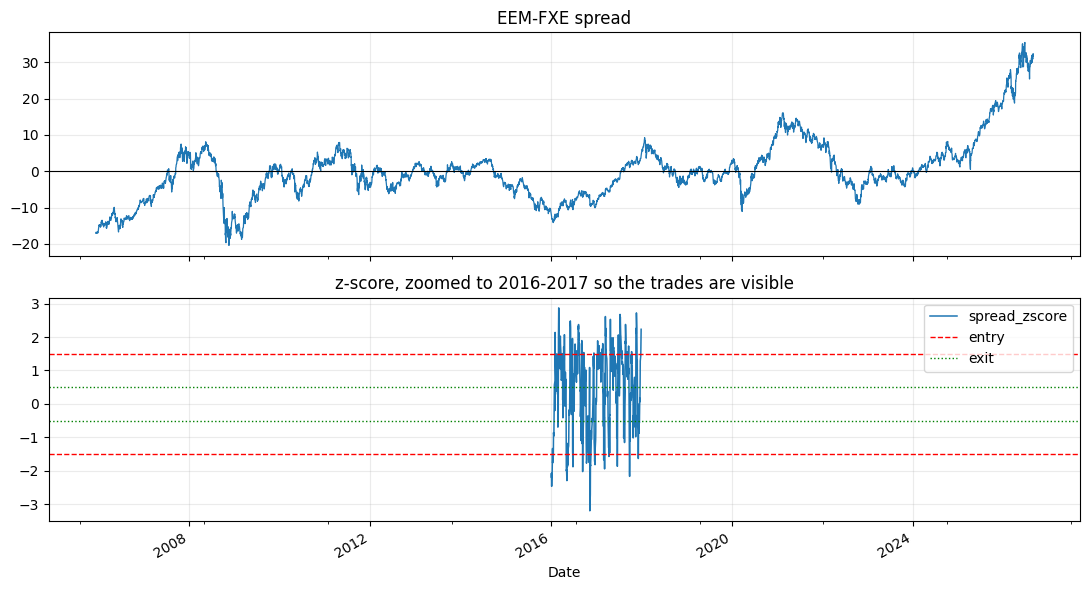

In [7]:
# The mechanics, shown on the pair the selection favours most.
asset_a, asset_b = pair_choices.value_counts().index[0].split("-")
spread_frame = build_spread(prices[asset_a], prices[asset_b])
spread_zscore = compute_spread_zscore(spread_frame["spread"], window=PAIRS_CONFIG.zscore_window)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
spread_frame["spread"].plot(ax=axes[0], color="tab:blue", lw=0.9)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title(f"{asset_a}-{asset_b} spread")
spread_zscore.loc["2016":"2017"].plot(ax=axes[1], color="tab:blue", lw=1.1)
axes[1].axhline(PAIRS_CONFIG.entry_threshold, color="red", ls="--", lw=1, label="entry")
axes[1].axhline(-PAIRS_CONFIG.entry_threshold, color="red", ls="--", lw=1)
axes[1].axhline(PAIRS_CONFIG.exit_threshold, color="green", ls=":", lw=1, label="exit")
axes[1].axhline(-PAIRS_CONFIG.exit_threshold, color="green", ls=":", lw=1)
axes[1].set_title("z-score, zoomed to 2016-2017 so the trades are visible")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Does the edge survive the specification choices?

A Sharpe of about 0.38 looks like a modest success. Before believing it, two choices buried inside
the rule are worth testing, because theory says neither should matter much.

**Levels or logs.** Notebook 1 showed log prices are the better-founded basis for the spread:

$$X_t = P^{A}_t - \alpha - \beta P^{B}_t
\qquad\text{versus}\qquad
X_t = \log P^{A}_t - \alpha - \beta \log P^{B}_t,$$

where on levels $\beta$ carries units of B per unit of A and drifts as prices grow apart, while on
logs it is a scale-free elasticity.

**Unit or hedge-weighted legs.** This one is a genuine inconsistency. The rule estimates $\beta$ to
*define* the spread, then trades $\pm 1$ on each leg and discards it, so the portfolio held is not
the spread whose stationarity was tested. Weighting the legs by the hedge ratio,

$$w^{A}_t = \frac{s_t}{1 + |\beta|}, \qquad w^{B}_t = \frac{-\,s_t\,\beta}{1 + |\beta|},$$

makes the trade match the signal, and roughly halves turnover.

`pair_specification_grid` re-runs the **entire** walk-forward selection under all four combinations,
refitting every pair's hedge ratio on every training window, so the comparison is like for like.

In [8]:
from src.analysis.robustness import pair_specification_grid

spec_grid = pair_specification_grid(
    prices, returns, calendar, transaction_cost_bps=TC, slippage_bps=SLIP, **wf_kwargs)
spec_grid.round(3)

,net_sharpe,cagr,max_drawdown,ann_turnover,most_selected_pair
"levels, unit legs",0.376683,0.066415,-0.396114,64.630705,EEM-FXE
"logs, unit legs",0.221135,0.023552,-0.602669,62.041494,EEM-USO
"levels, hedge-weighted",0.180819,0.015714,-0.381078,31.3551,EEM-FXE
"logs, hedge-weighted",0.176189,0.011783,-0.42113,32.685695,EEM-UUP


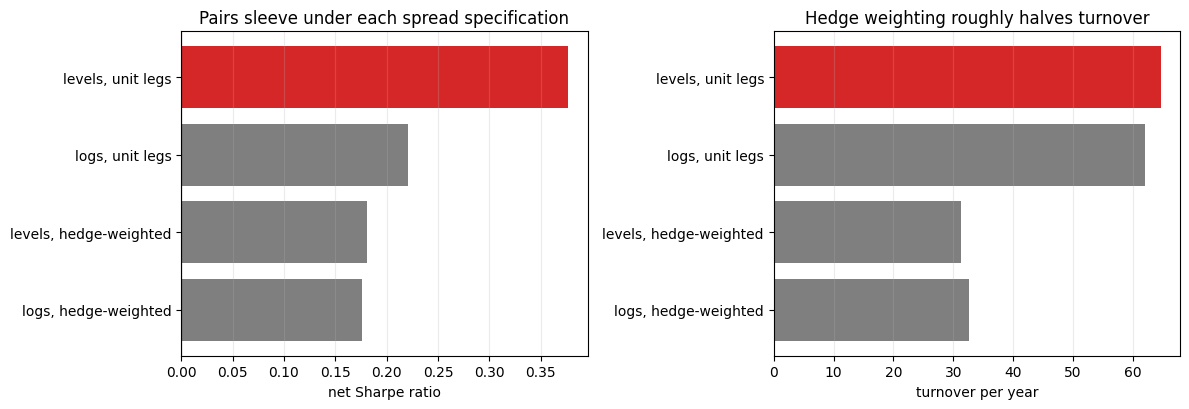

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
labels = list(spec_grid.index)
colours = ["tab:red" if "levels, unit" in name else "tab:gray" for name in labels]

ax1.barh(labels, spec_grid["net_sharpe"].astype(float), color=colours)
ax1.set_xlabel("net Sharpe ratio")
ax1.set_title("Pairs sleeve under each spread specification")
ax1.axvline(0, color="black", lw=0.8)
ax1.invert_yaxis()

ax2.barh(labels, spec_grid["ann_turnover"].astype(float), color=colours)
ax2.set_xlabel("turnover per year")
ax2.set_title("Hedge weighting roughly halves turnover")
ax2.invert_yaxis()
for ax in (ax1, ax2):
    ax.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.show()

### Verdict: rejected

The specification that is hardest to defend on theory, price levels with unit legs, is the one that
performs best. Switching to logs roughly halves the Sharpe ratio. Making the trade internally
consistent halves it again, even though it also halves turnover, which should have *helped* a rule
trading 65 times a year.

The sub-period patterns do not merely shift, they reorganize: levels with unit legs earns its best
Sharpe in 2006-09 and its worst in 2014-17, while logs with unit legs does close to the opposite.

A genuine edge should not behave this way under changes theory says are close to innocuous. The
whole result sits inside the noise of arbitrary implementation, so **pairs trading is rejected and
receives no capital**. It appears in no portfolio in notebook 3, and in none of the robustness or
risk analysis that follows.

What the exercise is worth keeping for is the method. Hard-coding a pair gave a clearly negative
result; selecting the pair without hindsight appeared to rescue it; testing the remaining
specification choices showed the rescue was illusory. A negative result can be a verdict on one
arbitrary choice rather than on an idea, which is worth checking, but the check has to be run on
*every* arbitrary choice before the answer can be trusted.

## Strategy C - Regime switching

Idea: stay invested in the bull regime, hold 35% in the sideways regime, step aside in the crisis
regime. States are interpreted by their average return.

In [10]:
hmm_model = fit_hmm_regime_model(regime_features)  # Fit the Hidden Markov Model.
regime_table = map_regimes_to_labels(infer_regimes(hmm_model, regime_features), benchmark_log_returns)
regime_labels = regime_table["regime_label"]
regime_positions = regime_based_positions(regime_labels, benchmark_asset)  # Convert labels into weights.

regime_backtest = positions_to_strategy_returns(regime_positions, returns, TC, SLIP)
pd.Series(performance_metrics(regime_backtest["net_return"]),
          name="Regime switching (construction check)").to_frame()

,Regime switching (construction check)
sharpe_ratio,0.821332
sortino_ratio,0.950270
cagr,0.061817
max_drawdown,-0.138185
calmar_ratio,0.447349
volatility,0.076621
var_95,0.007658
expected_shortfall_95,0.012251


## Strategy D - Adaptive asset allocation (AAA)

Idea: hold whatever has been working across the ETF menu, size the holdings so each carries similar
risk, and step out of anything that is falling.

At every month-end:

1. rank the eight ETFs by 6-month total return (**relative momentum**),
2. keep the top half,
3. weight the survivors by **inverse volatility**, so a calm asset gets a bigger share than a wild one,
4. if a selected asset's own 6-month return is negative, move its weight to the defensive asset
   (**absolute momentum**). TLT is the defensive asset because it is the only bond fund here.

Nothing is estimated: every weight is a deterministic function of trailing prices. That makes the
rule causal by construction, which the test suite verifies directly.

With the ragged panel, an asset with too little history has a missing momentum and a missing
volatility, so it is automatically excluded from both the ranking and the weight normalization.

In [11]:
print("menu:", adaptive_allocation.resolve_menu(), "| lookback:", AAA_CONFIG.lookback,
      "| top_n:", AAA_CONFIG.top_n, "| defensive:", AAA_CONFIG.defensive_asset)

# aaa_positions was built with the shared signals above.
aaa_backtest = positions_to_strategy_returns(aaa_positions, returns, TC, SLIP)
pd.Series(performance_metrics(aaa_backtest["net_return"]), name="AAA (construction check)").to_frame()

menu: ['SPY', 'TLT', 'GLD', 'USO', 'UUP', 'EFA', 'EEM', 'FXE'] | lookback: 126 | top_n: 4 | defensive: TLT


,AAA (construction check)
sharpe_ratio,1.002919
sortino_ratio,1.333991
cagr,0.109233
max_drawdown,-0.173193
calmar_ratio,0.630701
volatility,0.109357
var_95,0.010821
expected_shortfall_95,0.016381


In [12]:
# Which assets does the rule actually use, and how often?
adaptive_allocation.describe_positions(aaa_positions).round(3)

,share_of_days_held,average_weight_when_held
SPY,0.695,0.278
EFA,0.566,0.251
EEM,0.541,0.187
TLT,0.535,0.350
GLD,0.492,0.218
USO,0.371,0.133
UUP,0.342,0.394
FXE,0.204,0.396


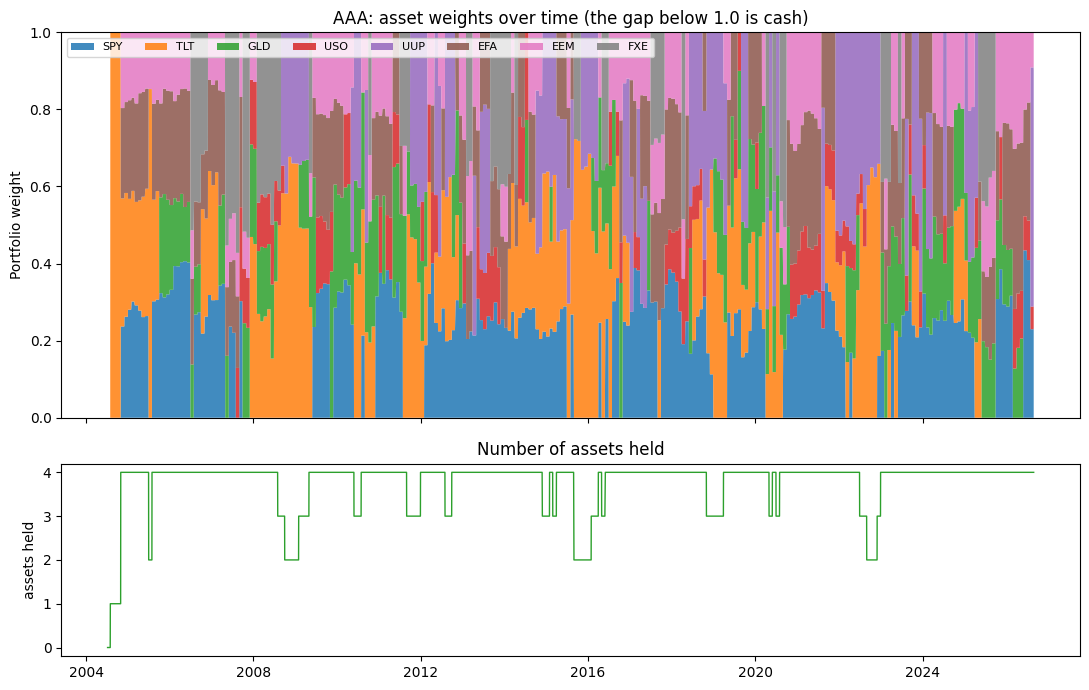

In [13]:
held = aaa_positions.loc[:, aaa_positions.abs().sum() > 0]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].stackplot(held.index, [held[c].values for c in held.columns], labels=list(held.columns), alpha=0.85)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Portfolio weight")
axes[0].set_title("AAA: asset weights over time (the gap below 1.0 is cash)")
axes[0].legend(ncol=8, fontsize=8, loc="upper left")
axes[1].plot((aaa_positions > 1e-8).sum(axis=1), lw=1.0, color="tab:green")
axes[1].set_ylabel("assets held")
axes[1].set_title("Number of assets held")
plt.tight_layout()
plt.show()

## Step 2 - Compare the four constructed strategies

Benchmarks are SPY buy-and-hold and a monthly rebalanced 60/40 (SPY/TLT), both charged the same
costs. These are still construction checks: the rules were specified with knowledge of the whole
sample, so the honest numbers come in the next section.

In [14]:
spy_backtest = positions_to_strategy_returns(buy_and_hold_positions(returns.index, benchmark_asset), returns, TC, SLIP)
sixty_forty_backtest = positions_to_strategy_returns(sixty_forty_positions(returns.index, benchmark_asset, "TLT"), returns, TC, SLIP)

backtests = {
    "volatility_timing": vol_timing_backtest, "pairs_trading": pairs_backtest,
    "regime_switching": regime_backtest, "adaptive_allocation": aaa_backtest,
}
constructed = pd.DataFrame({STRATEGY_LABELS[n]: bt["net_return"] for n, bt in backtests.items()})
constructed["SPY"] = spy_backtest["net_return"]
constructed["60/40"] = sixty_forty_backtest["net_return"]

table = pd.DataFrame({name: performance_metrics(constructed[name].dropna()) for name in constructed.columns})
table.loc["ann_turnover"] = pd.Series({STRATEGY_LABELS[n]: bt["turnover"].mean() * 252 for n, bt in backtests.items()})
table.loc["start"] = constructed.apply(lambda s: s.dropna().index.min().date())
table.index.name = "metric"
table

,VolTiming,Pairs,RegimeHMM,AAA,SPY,60/40
metric,,,,,,
sharpe_ratio,1.050865,0.376683,0.821332,1.002919,0.645721,0.80974
sortino_ratio,1.40618,0.404182,0.95027,1.333991,0.790242,1.056681
cagr,0.156836,0.066415,0.061817,0.109233,0.10853,0.086426
max_drawdown,-0.180342,-0.396114,-0.138185,-0.173193,-0.551894,-0.299228
calmar_ratio,0.869658,0.167667,0.447349,0.630701,0.19665,0.288829
volatility,0.14931,0.262035,0.076621,0.109357,0.186567,0.10983
var_95,0.015732,0.022253,0.007658,0.010821,0.017047,0.010261
expected_shortfall_95,0.022386,0.03905,0.012251,0.016381,0.028485,0.016211
ann_turnover,7.200512,64.630705,3.549921,5.730307,NaN,NaN


## Step 3 - Walk-forward out-of-sample validation

This is where the results come from.

The blocks above fit each model **once** on all available history and give AAA and the pair their
configured settings. Here we run an **expanding walk-forward** on one shared calendar:

* the **model-based** strategies (random forest, HMM, pair hedge ratio) are refit on every expanding
  training prefix and traded only on the following 21-day test block, with regime labels built from
  training-window returns only;
* **AAA has no model to fit**, so the walk-forward instead *selects its parameters*. On each fold,
  every candidate (lookback, top-N) pair is scored by its net Sharpe on the training window, and the
  winner is traded on the next block;
* the **pairs sleeve** goes one step further and selects *which pair to trade*. Each pair's hedge
  ratio is already refit per fold, so scoring the pairs on training-window Sharpe adds an outer layer
  of walk-forward rather than reintroducing hindsight.

This answers "what would I have earned without knowing the right lookback, or the right pair, in
advance?".

The random-forest refits take several minutes, so `REUSE_CACHE = True` loads the positions written
by `run_research.py`.

In [15]:
REUSE_CACHE = True
cache_dir = project_root / "results" / "cache"
cache_files = {n: cache_dir / f"wf_positions_{n}.csv" for n in STRATEGY_LABELS}

candidates = adaptive_allocation_candidates(prices)  # Position table for every parameter set.

if REUSE_CACHE and all(f.exists() for f in cache_files.values()):
    wf_positions = {n: pd.read_csv(f, index_col=0, parse_dates=True) for n, f in cache_files.items()}
    wf_choices = pd.read_csv(cache_dir / "wf_parameter_choices.csv", index_col=0, parse_dates=True)
    print("loaded cached walk-forward positions")
else:
    wf_positions = {
        "volatility_timing": walk_forward_volatility_positions(
            volatility_features, benchmark_asset, calendar=calendar, **wf_kwargs),
        "regime_switching": walk_forward_regime_positions(
            regime_features, benchmark_log_returns, benchmark_asset, calendar=calendar, **wf_kwargs),
        "pairs_trading": pairs_positions,  # already selected in Strategy B
    }
    wf_positions["adaptive_allocation"], aaa_choices = walk_forward_rule_positions(
        candidates, returns, calendar=calendar, transaction_cost_bps=TC, slippage_bps=SLIP, **wf_kwargs)
    wf_choices = pd.DataFrame({"adaptive_allocation": aaa_choices, "pairs_trading": pair_choices})

wf_backtests = {n: positions_to_strategy_returns(p, returns, TC, SLIP) for n, p in wf_positions.items()}
strategies = pd.DataFrame({STRATEGY_LABELS[n]: bt["net_return"] for n, bt in wf_backtests.items()})
oos_start = strategies.dropna(how="all").index.min()
print("out-of-sample window:", oos_start.date(), "to", strategies.index.max().date())

loaded cached walk-forward positions
out-of-sample window: 2006-07-05 to 2026-08-17


In [16]:
# THE results table: every strategy, walk-forward, net of costs, on one window.
results = pd.DataFrame({name: performance_metrics(strategies[name].dropna()) for name in strategies.columns})
results["SPY"] = pd.Series(performance_metrics(constructed["SPY"].loc[oos_start:]))
results["60/40"] = pd.Series(performance_metrics(constructed["60/40"].loc[oos_start:]))
results.loc["ann_turnover"] = pd.Series({STRATEGY_LABELS[n]: bt["turnover"].mean() * 252 for n, bt in wf_backtests.items()})
results.index.name = "metric"
results

,VolTiming,Pairs,RegimeHMM,AAA,SPY,60/40
metric,,,,,,
sharpe_ratio,0.809933,0.376683,0.747012,0.830620,0.651682,0.817364
sortino_ratio,1.045011,0.404182,0.831201,1.095326,0.795017,1.061075
cagr,0.106815,0.066415,0.061845,0.085941,0.113480,0.090012
max_drawdown,-0.301800,-0.396114,-0.149457,-0.173193,-0.551894,-0.299228
calmar_ratio,0.353928,0.167667,0.413800,0.496217,0.205619,0.300816
volatility,0.136941,0.262035,0.085215,0.106054,0.193817,0.113314
var_95,0.014460,0.022253,0.008284,0.010611,0.017940,0.010641
expected_shortfall_95,0.021230,0.039050,0.014003,0.016052,0.029763,0.016807
ann_turnover,6.806805,64.630705,11.424896,6.776684,NaN,NaN


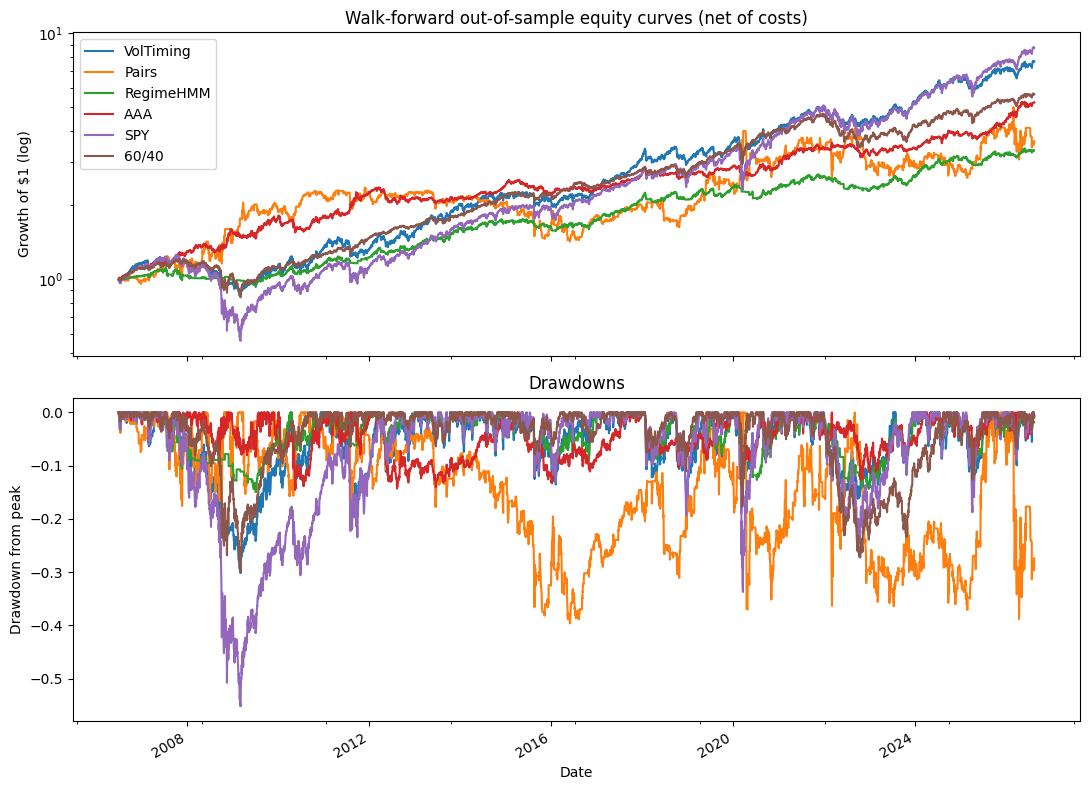

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
curves = strategies.apply(lambda c: equity_curve(c.dropna()))
curves["SPY"] = equity_curve(constructed["SPY"].loc[oos_start:])
curves["60/40"] = equity_curve(constructed["60/40"].loc[oos_start:])
curves.plot(ax=axes[0], title="Walk-forward out-of-sample equity curves (net of costs)", logy=True)
axes[0].set_ylabel("Growth of $1 (log)")
curves.apply(drawdown_curve).plot(ax=axes[1], title="Drawdowns", legend=False)
axes[1].set_ylabel("Drawdown from peak")
plt.tight_layout()
plt.show()

adaptive_allocation
lb126_top4    0.502
lb63_top5     0.494
lb63_top4     0.004


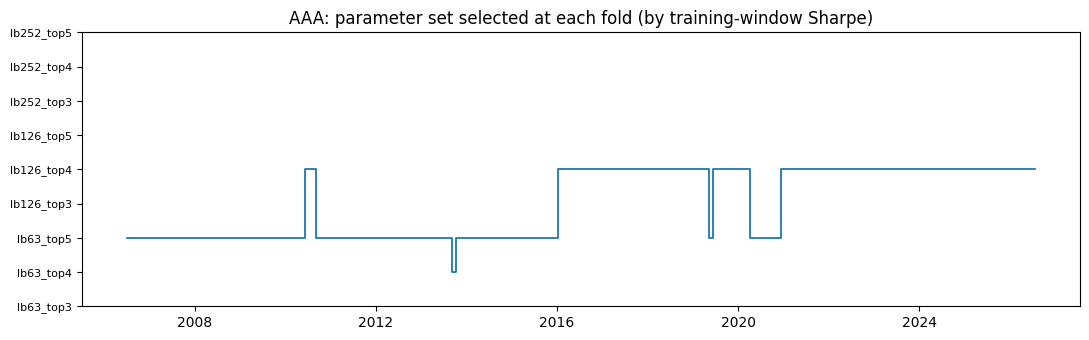

In [18]:
# Which parameter set did the walk-forward choose for AAA, and how often?
shares = wf_choices["adaptive_allocation"].value_counts(normalize=True).round(3)
print(shares.to_string())

codes = wf_choices["adaptive_allocation"].map({c: i for i, c in enumerate(candidates)})
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.step(codes.index, codes.values, where="post", lw=1.3)
ax.set_yticks(range(len(candidates)))
ax.set_yticklabels(list(candidates), fontsize=8)
ax.set_title("AAA: parameter set selected at each fold (by training-window Sharpe)")
plt.tight_layout()
plt.show()

### Reading the results

* **AAA is the strongest single rule** out of sample and the only one that made money through 2008.
* The two SPY-based rules survive but correlate about 0.84 with each other, since both are scaled
  SPY exposure. Notebook 3 shows why that limits what they can do for a portfolio.
* **Pairs trading is rejected** for the reasons set out in Strategy B. It appears in the table below
  for completeness and is then dropped: no portfolio in notebook 3 holds it, and it appears in none
  of the robustness or risk analysis.
* Walk-forward Sharpe is lower than the construction check for every strategy. That gap is the value
  of hindsight, and it is why the construction numbers are not reported as results.